# Tabular prediction: information boundaries and decisions
        Inspect the completed Adult benchmark, verify partition isolation, and derive an
        operating threshold from a declared utility. [Protocol](../docs/02_tabular_decisions.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
metrics = evidence('classification')
table = pd.DataFrame(metrics['rows'])
table.groupby('model')[['roc_auc', 'average_precision', 'log_loss', 'brier', 'set_coverage', 'set_size']].agg(['mean', 'std'])

roc_auc           average_precision            log_loss  \
                    mean       std              mean       std      mean   
model                                                                      
hist_boosting   0.925691  0.000585          0.822395  0.001826  0.279611   
logistic        0.903512  0.000763          0.758621  0.001986  0.320413   
tabular_resnet  0.908995  0.003870          0.776658  0.008749  0.310441   

                             brier           set_coverage            set_size  \
                     std      mean       std         mean       std      mean   
model                                                                           
hist_boosting   0.001073  0.088920  0.000494     0.898716  0.001574  1.060029   
logistic        0.001154  0.102678  0.000397     0.903937  0.004489  1.121942   
tabular_resnet  0.006353  0.099284  0.001902     0.896259  0.003619  1.089532   

                          
                     std  
model                     
hist_boosting   0.001459  
logistic        0.013517  
tabular_resnet  0.009503

## Confirm that four training partitions do not overlap
        The official test is a separate file. Preprocessing sees fitting rows only.
        Calibration is distinct from settings and threshold selection.

In [3]:
split = json.loads((root/'results/reference/classification/split_0.json').read_text())
parts = [np.array(split[k]) for k in ['fit', 'validation', 'probability_calibration', 'conformal_calibration']]
assert len(np.unique(np.concatenate(parts))) == sum(map(len, parts))
assert sum(map(len, parts)) == metrics['data']['train']
print({k: len(split[k]) for k in ['fit', 'validation', 'probability_calibration', 'conformal_calibration']})

{'fit': 22792, 'validation': 3256, 'probability_calibration': 3256, 'conformal_calibration': 3257}


## Decisions are not the same as probability ranking
        If a false positive costs 1 and a false negative costs 2, predicting positive
        has expected cost $1-p$ and predicting negative costs $2p$. The Bayes threshold
        is therefore $1/3$, under calibrated probabilities and those particular costs.

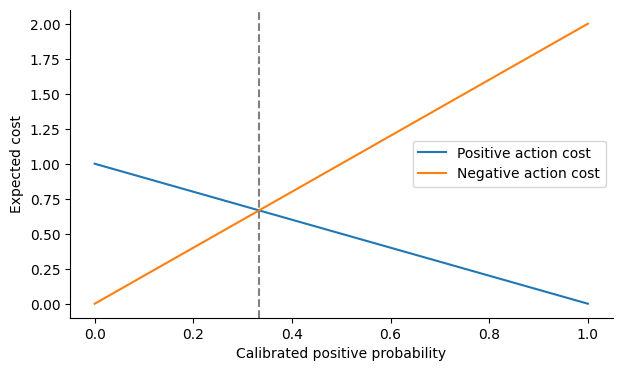

,model,seed,decision_threshold,decision_cost
0,logistic,0,0.33,0.225478
1,hist_boosting,0,0.39,0.198944
2,tabular_resnet,0,0.33,0.223512
3,logistic,1,0.38,0.226460
4,hist_boosting,1,0.37,0.198514
5,tabular_resnet,1,0.36,0.215036
6,logistic,2,0.33,0.224372
7,hist_boosting,2,0.25,0.198268
8,tabular_resnet,2,0.26,0.218598


In [4]:
probabilities = np.linspace(0, 1, 200)
plt.plot(probabilities, 1-probabilities, label='Positive action cost')
plt.plot(probabilities, 2*probabilities, label='Negative action cost')
plt.axvline(1/3, color='gray', linestyle='--')
plt.xlabel('Calibrated positive probability'); plt.ylabel('Expected cost'); plt.legend(); plt.show()
table[['model', 'seed', 'decision_threshold', 'decision_cost']]

## Diagnostic subgroup behavior
        Marginal coverage does not guarantee every subgroup's coverage. Keep sample sizes
        next to scores and avoid turning descriptive differences into causal claims.

In [5]:
groups = pd.DataFrame(metrics['diagnostics_seed0']['hist_boosting']['groups'])
groups[['feature','group','n','roc_auc','log_loss','set_coverage','tpr','fpr']]

,feature,group,n,roc_auc,log_loss,set_coverage,tpr,fpr
0,sex,Female,5421,0.942752,0.163652,0.949456,0.676271,0.037052
1,sex,Male,10860,0.907824,0.337369,0.873665,0.748157,0.136507
2,race,Amer-Indian-Eskimo,159,0.967293,0.159806,0.949686,0.842105,0.042857
3,race,Asian-Pac-Islander,480,0.899590,0.353927,0.866667,0.721805,0.132565
4,race,Black,1561,0.946978,0.166806,0.941063,0.653631,0.044139
5,race,Other,135,0.972727,0.185030,0.948148,0.760000,0.009091
6,race,White,13946,0.922269,0.291863,0.894235,0.741261,0.105490


In [6]:
pd.DataFrame(metrics['paired_seed0'])

,comparison,difference,ci95,repeats,unit
0,hist_boosting minus logistic NLL,-0.041421,"[-0.045612887838455934, -0.037052411934888736]",1000,test example
1,tabular_resnet minus logistic NLL,-0.003264,"[-0.007104973248045983, 0.0012655825491535394]",1000,test example


## Exercise and worked answer
        Can model selection use the conformal-calibration labels and still rely on the
        simple split-conformal proof? No. Those scores need to come from a predictor fixed
        without fitting or selection on the calibration labels. A separate calibration
        partition makes the data dependence explicit. The actual income benchmark is
        historical; the costs above are an illustration, not a hiring recommendation.